# 08 – SQ5: closed ski lifts in Italy and the "at risk" group (chi-squared test)

**Requirements:** statistical test with a p-value (extra point: chi-squared test) · **Data:** table `closures` (Legambiente, Nevediversa 2026, built in notebook 04) and table `resorts` (skiresort.info, notebooks 02–05) in `db/sci_alpi.db`

**Question (SQ5).** Do the ski facilities that Legambiente lists as closed ("dismesso" = permanently closed, "chiuso temporaneamente" = temporarily closed) fall into the **"at risk" group** more often than the ski areas that are still operating?

**Method.** The chi-squared test of independence compares *observed* counts in a 2 × 2 table with the counts we would *expect* if the group (closed / operating) had nothing to do with the risk class. A small p-value says: the difference is unlikely to be chance alone. It never says *why* the difference exists.

1. **Test A (main question):** group (closed facility / operating area) × risk class (at risk / not at risk).
2. **Test B (literal "status × risk class"):** within the closed facilities, status (permanently / temporarily closed) × risk class.
3. **Sensitivity:** the result must not depend on one arbitrary threshold or one arbitrary way of comparing a single lift with a whole ski area.

> **PROVISIONAL.** The real snow-risk class (days with at least 30 cm of natural snow per winter, SQ1) does **not** exist yet for the closed facilities, because the snow data for all places are still being decided (see `data/processed/data_status.json`). Until then the **risk class is an altitude proxy**: *midpoint altitude of the facility below 1,500 m = at risk*. Altitude is the strongest single driver of natural snow reliability in the Alps, but it is a proxy and the 1,500 m line is a rule of thumb, not a result of this project. The test code does not change when the proxy is replaced: only the column `at_risk` in section 2 has to be rebuilt from the snow data.

In [1]:
import json
import re
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from scipy import stats

ROOT = Path.cwd()
while not (ROOT / "requirements.txt").exists():
    ROOT = ROOT.parent
DB_PATH = ROOT / "db" / "sci_alpi.db"
FIG_DIR = ROOT / "docs" / "figures"
OUT_DIR = ROOT / "data" / "processed"
FIG_DIR.mkdir(parents=True, exist_ok=True)
assert DB_PATH.exists(), "Run notebook 05_sqlite_database.ipynb first (it creates db/sci_alpi.db)."

con = sqlite3.connect(f"file:{DB_PATH}?mode=ro", uri=True)
closures = pd.read_sql_query("SELECT * FROM closures", con)
resorts = pd.read_sql_query("SELECT * FROM resorts", con)
con.close()

status = json.loads((OUT_DIR / "data_status.json").read_text())
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

INK, INK_SOFT, GRID = "#0b0b0b", "#52514e", "#e3e2de"
COLOR_CLOSED, COLOR_OPEN = "#D55E00", "#0072B2"
plt.rcParams.update({"font.size": 11, "axes.edgecolor": GRID, "axes.labelcolor": INK_SOFT,
                     "xtick.color": INK_SOFT, "ytick.color": INK_SOFT, "text.color": INK,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "axes.axisbelow": True})
print(len(closures), "closed facilities;", len(resorts), "ski areas in the table resorts")

184 closed facilities; 293 ski areas in the table resorts


## 1. Data and scope

**Closed facilities.** Legambiente publishes, for each facility, a text such as `1400 m s.l.m. - 1650 m s.l.m.` (altitude of lower and upper station; *s.l.m.* = above sea level). The text must be turned into numbers. Italian writing uses a dot as thousands separator (`3.486 m` = 3,486 m), so the dot is removed before the numbers are read. The function is tested on real examples from the report.

**Operating areas.** The Italian ski areas of the Alpine analysis set from `resorts` (notebook 02.4): base and top elevation from skiresort.info.

**Scope.** Legambiente also lists facilities in the Apennines and on the islands (Abruzzo, Emilia-Romagna, Toscana, Lazio, ...). The operating areas of this project are Alpine, so the **main comparison uses the Alpine regions only** (Valle d'Aosta, Piemonte, Lombardia, Trentino-Alto Adige, Veneto, Friuli Venezia Giulia). Piemonte contains a few non-Alpine places; this is a known imperfection. The whole of Italy is shown as a sensitivity check.

In [2]:
def parse_altitudes(text):
    # Return all altitudes (in metres) found in a Legambiente altitude text.
    # The dot in '3.486' is a thousands separator, so it is removed first.
    if not isinstance(text, str):
        return []
    cleaned = re.sub(r"(\d)\.(\d{3})", r"\1\2", text)
    return [int(x) for x in re.findall(r"\d{3,4}", cleaned)]

# Tests on real examples from the report
assert parse_altitudes("730 s.l.m. m") == [730]
assert parse_altitudes("1400 m s.l.m - 1650 m s.l.m") == [1400, 1650]
assert parse_altitudes("2400 m s.l.m. - 3.486 m s.l.m.") == [2400, 3486]
assert parse_altitudes("circa 2200 m s.l.m.") == [2200]
assert parse_altitudes("1370 m s.l.m. -1250 m s.l.m. circa.") == [1370, 1250]
assert parse_altitudes(None) == []

closures = closures.copy()
closures["alts"] = closures["altitude_text"].map(parse_altitudes)
assert closures["alts"].map(len).between(1, 2).all(), "every altitude text must give one or two numbers"
closures["alt_low"] = closures["alts"].map(min)
closures["alt_top"] = closures["alts"].map(max)
closures["alt_mid"] = (closures["alt_low"] + closures["alt_top"]) / 2
assert closures["alt_top"].between(400, 4000).all()

ALPINE_REGIONS = ["Valle d\u2019Aosta", "Piemonte", "Lombardia", "Trentino-Alto Adige", "Veneto", "Friuli Venezia Giulia"]
closures["alpine_region"] = closures["region"].isin(ALPINE_REGIONS)

operating = resorts[(resorts["country"] == "IT") & (resorts["in_alpine_analysis_set"] == 1)].copy()
operating["alt_mid"] = (operating["elevation_base_m"] + operating["elevation_top_m"]) / 2
assert operating[["elevation_base_m", "elevation_top_m"]].notna().all().all()
assert (operating["elevation_top_m"] > operating["elevation_base_m"]).all()

closed_alp = closures[closures["alpine_region"]].copy()
print("Closed facilities in Alpine regions:", len(closed_alp), "of", len(closures), "in the report")
print("Operating Italian Alpine areas:     ", len(operating))
pd.concat([closures["region"].value_counts().rename("closed facilities (all Italy)"),
           closed_alp["region"].value_counts().rename("closed, Alpine regions")], axis=1).fillna(0).astype(int)

Closed facilities in Alpine regions: 116 of 184 in the report
Operating Italian Alpine areas:      69


,closed facilities (all Italy),"closed, Alpine regions"
region,,
Piemonte,45,45
Lombardia,34,34
Veneto,19,19
Emilia-Romagna,18,0
Abruzzo,15,0
Friuli Venezia Giulia,8,8
Toscana,7,0
Valle d’Aosta,6,6
Lazio,5,0


## 2. The risk class (provisional proxy)

**Why the midpoint altitude.** A closed lift is one line between a lower and an upper station. An operating *area* has many lifts spread over its whole vertical range. The fair comparison is therefore *the middle of a closed lift* against *the middle of an operating area* (`(base + top) / 2`). Comparing the upper station of a lift with the summit of a whole area would make closed lifts look low only because a single lift rarely reaches the summit; that comparison is shown in section 5 as a deliberately biased check.

**Why 1,500 m.** It is a common rule of thumb for the lower limit of snow-reliable skiing in the Alps. It is **not** derived here. To avoid depending on one number, 1,200 m and 1,800 m are tested too. The decision rule is fixed *before* looking at the results: the main test uses 1,500 m.

In [3]:
THRESHOLD_MAIN = 1500   # metres; fixed in advance, sensitivity at 1200 and 1800 in section 5

closed_alp["at_risk"] = closed_alp["alt_mid"] < THRESHOLD_MAIN
operating["at_risk"] = operating["alt_mid"] < THRESHOLD_MAIN

summary = pd.DataFrame({
    "closed (Alpine regions)": closed_alp["alt_mid"].describe(),
    "operating (Italian Alps)": operating["alt_mid"].describe(),
}).round(0)
display(summary)
print("Share of facilities below", THRESHOLD_MAIN, "m  ->  closed:", round(closed_alp["at_risk"].mean(), 3),
      "| operating:", round(operating["at_risk"].mean(), 3))

,closed (Alpine regions),operating (Italian Alps)
count,116.0,69.0
mean,1466.0,1879.0
std,465.0,319.0
min,613.0,1253.0
25%,1180.0,1645.0
50%,1400.0,1880.0
75%,1696.0,2052.0
max,2957.0,3105.0


Share of facilities below 1500 m  ->  closed: 0.586 | operating: 0.087


## 3. Test A – closed facility or operating area × risk class

**How to read a chi-squared test (step by step).**

1. Put the counts in a 2 × 2 table: rows = group, columns = at risk / not at risk.
2. For every cell compute the **expected** count if group and risk were unrelated: `row total × column total / grand total`.
3. Add up `(observed − expected)² / expected` over the four cells. This is the **chi-squared statistic**: 0 means "exactly as expected", larger means "further from independence".
4. The **p-value** is the probability of a statistic at least this large *if* group and risk were unrelated. Rule of thumb: p < 0.05 = unlikely to be chance.
5. The test needs **expected counts of at least 5** in every cell; otherwise the **Fisher exact test** is used.

Besides the p-value two effect sizes are reported, because with enough data every tiny difference becomes "significant": the **odds ratio** (how many times larger are the odds of being "at risk" for closed facilities; 1 = no difference) with its 95 % confidence interval, and **Cramér's V** (0 = no association, 1 = perfect association; about 0.1 small, 0.3 medium, 0.5 large).

In [4]:
def chi2_report(table, label):
    # table: 2x2 array [[closed_at_risk, closed_not], [open_at_risk, open_not]]
    t = np.asarray(table, dtype=float)
    assert t.shape == (2, 2) and (t >= 0).all()
    chi2, p, dof, expected = stats.chi2_contingency(t, correction=False)
    _, p_yates, _, _ = stats.chi2_contingency(t, correction=True)
    _, p_fisher = stats.fisher_exact(t)
    n = t.sum()
    # check against the manual formula from the explanation above
    manual = ((t - expected) ** 2 / expected).sum()
    assert abs(manual - chi2) < 1e-9
    # odds ratio with Haldane-Anscombe correction (+0.5) when a cell is 0, Woolf confidence interval
    a, b, c, d = t.ravel() + (0.5 if (t == 0).any() else 0.0)
    odds_ratio = (a * d) / (b * c)
    se = np.sqrt(1 / a + 1 / b + 1 / c + 1 / d)
    return {"test": label, "n": int(n), "closed_at_risk": int(t[0, 0]), "closed_not": int(t[0, 1]),
            "other_at_risk": int(t[1, 0]), "other_not": int(t[1, 1]),
            "chi2": chi2, "dof": dof, "p_value": p, "p_yates": p_yates, "p_fisher": p_fisher,
            "min_expected": expected.min(), "cramers_v": float(np.sqrt(chi2 / n)),
            "odds_ratio": odds_ratio, "or_ci_low": float(np.exp(np.log(odds_ratio) - 1.96 * se)),
            "or_ci_high": float(np.exp(np.log(odds_ratio) + 1.96 * se)),
            "haldane_correction": bool((t == 0).any())}, expected

tab_a = [[int(closed_alp["at_risk"].sum()), int((~closed_alp["at_risk"]).sum())],
         [int(operating["at_risk"].sum()), int((~operating["at_risk"]).sum())]]
res_a, exp_a = chi2_report(tab_a, "A: closed vs operating x at risk (mid altitude < 1500 m)")

obs_df = pd.DataFrame(tab_a, index=["closed facility", "operating area"], columns=["at risk (< 1500 m)", "not at risk"])
exp_df = pd.DataFrame(exp_a, index=obs_df.index, columns=obs_df.columns).round(1)
print("Observed counts"); display(obs_df)
print("Expected counts if group and risk were unrelated"); display(exp_df)
print(f"chi-squared = {res_a['chi2']:.2f}, degrees of freedom = {res_a['dof']}, p = {res_a['p_value']:.2e}")
print(f"with Yates correction p = {res_a['p_yates']:.2e}; Fisher exact p = {res_a['p_fisher']:.2e}; smallest expected count = {res_a['min_expected']:.1f}")
print(f"odds ratio = {res_a['odds_ratio']:.1f} (95% CI {res_a['or_ci_low']:.1f} to {res_a['or_ci_high']:.1f}); Cramer's V = {res_a['cramers_v']:.2f}")
assert res_a["min_expected"] >= 5, "chi-squared not valid: use Fisher"

Observed counts


,at risk (< 1500 m),not at risk
closed facility,68,48
operating area,6,63


Expected counts if group and risk were unrelated


,at risk (< 1500 m),not at risk
closed facility,46.4,69.6
operating area,27.6,41.4


chi-squared = 44.93, degrees of freedom = 1, p = 2.04e-11
with Yates correction p = 5.83e-11; Fisher exact p = 2.30e-12; smallest expected count = 27.6
odds ratio = 14.9 (95% CI 6.0 to 37.2); Cramer's V = 0.49


## 4. Test B – status of the closed facilities × risk class

This is the table named in the project plan ("status × risk class"). It asks something different from test A: among the closed facilities, are the *permanently* closed ones ("dismesso") more often in the at-risk class than the *temporarily* closed ones? The temporary group is small (14 Alpine facilities), so the Fisher exact test is reported next to the chi-squared test.

In [5]:
closed_alp["permanent"] = closed_alp["status"] == "dismesso"
tab_b = [[int((closed_alp["permanent"] & closed_alp["at_risk"]).sum()), int((closed_alp["permanent"] & ~closed_alp["at_risk"]).sum())],
         [int((~closed_alp["permanent"] & closed_alp["at_risk"]).sum()), int((~closed_alp["permanent"] & ~closed_alp["at_risk"]).sum())]]
res_b, exp_b = chi2_report(tab_b, "B: permanently vs temporarily closed x at risk")
res_b["closed_at_risk"], res_b["other_at_risk"] = tab_b[0][0], tab_b[1][0]   # in test B the rows are the two statuses

print("Observed counts"); display(pd.DataFrame(tab_b, index=["dismesso (permanent)", "chiuso temporaneamente"], columns=obs_df.columns))
print(f"chi-squared = {res_b['chi2']:.2f}, p = {res_b['p_value']:.3f}; Yates p = {res_b['p_yates']:.3f}; Fisher exact p = {res_b['p_fisher']:.3f}; smallest expected count = {res_b['min_expected']:.1f}")
print(f"odds ratio = {res_b['odds_ratio']:.2f} (95% CI {res_b['or_ci_low']:.2f} to {res_b['or_ci_high']:.2f}); Cramer's V = {res_b['cramers_v']:.2f}")

Observed counts


,at risk (< 1500 m),not at risk
dismesso (permanent),63,39
chiuso temporaneamente,5,9


chi-squared = 3.44, p = 0.063; Yates p = 0.117; Fisher exact p = 0.084; smallest expected count = 5.8
odds ratio = 2.91 (95% CI 0.91 to 9.31); Cramer's V = 0.17


## 5. Sensitivity – does the answer depend on the choices?

Each row repeats test A with one choice changed:

* **threshold** 1,200 / 1,500 / 1,800 m;
* **how a lift is compared with an area:** *midpoint vs midpoint* (fair, main), *upper station vs area summit* (biased **towards** finding the effect: one lift is nearly always lower than the summit of its area), *lift midpoint vs area base* (biased **against** finding the effect: the base is the lowest point of the area);
* **scope:** Alpine regions only (main) or all of Italy;
* a **threshold-free** check, the Mann-Whitney test on the altitudes themselves.

The truth lies between the two biased bounds. If the conclusion survived even the check biased *against* it, it would be robust to this choice; the notebook reports honestly whether it does.

In [6]:
rows = []
def add(label, closed_values, open_values, threshold, family):
    t = [[int((closed_values < threshold).sum()), int((closed_values >= threshold).sum())],
         [int((open_values < threshold).sum()), int((open_values >= threshold).sum())]]
    r, _ = chi2_report(t, label)
    r["threshold_m"] = threshold
    r["family"] = family
    rows.append(r)

for thr in (1200, 1500, 1800):
    add(f"midpoint vs midpoint (main), {thr} m", closed_alp["alt_mid"], operating["alt_mid"], thr, "fair")
for thr in (1200, 1500, 1800):
    add(f"upper station vs area summit (biased towards effect), {thr} m", closed_alp["alt_top"], operating["elevation_top_m"], thr, "towards")
for thr in (1200, 1500, 1800):
    add(f"lift midpoint vs area base (biased against effect), {thr} m", closed_alp["alt_mid"], operating["elevation_base_m"], thr, "against")
add("all Italian regions, midpoint vs midpoint, 1500 m", closures["alt_mid"], operating["alt_mid"], 1500, "all_italy")

sens = pd.DataFrame(rows)
sens["share_closed_at_risk"] = sens["closed_at_risk"] / (sens["closed_at_risk"] + sens["closed_not"])
sens["share_open_at_risk"] = sens["other_at_risk"] / (sens["other_at_risk"] + sens["other_not"])
show = sens[["test", "share_closed_at_risk", "share_open_at_risk", "chi2", "p_value", "p_fisher", "odds_ratio", "cramers_v", "min_expected"]].copy()
display(show.round({"share_closed_at_risk": 3, "share_open_at_risk": 3, "chi2": 1, "p_value": 6, "p_fisher": 6, "odds_ratio": 1, "cramers_v": 2, "min_expected": 1}))

mw = stats.mannwhitneyu(closed_alp["alt_mid"], operating["alt_mid"], alternative="two-sided")
print(f"Mann-Whitney U on midpoint altitudes: U = {mw.statistic:.0f}, p = {mw.pvalue:.2e}; median closed {closed_alp['alt_mid'].median():.0f} m, median operating {operating['alt_mid'].median():.0f} m")

def family_summary(family):
    f = sens[sens["family"] == family]
    ok = int(((f["p_value"] < 0.05) & (f["odds_ratio"] > 1)).sum())
    return ok, len(f), f["odds_ratio"].min(), f["odds_ratio"].max(), f["p_value"].max()

for fam, name in [("fair", "fair comparison (main)"), ("towards", "biased towards the effect"), ("against", "biased against the effect")]:
    ok, n_f, or_min, or_max, p_max = family_summary(fam)
    print(f"{name}: significant with odds ratio > 1 in {ok} of {n_f} thresholds; odds ratio {or_min:.2f} to {or_max:.2f}; largest p = {p_max:.4f}")

,test,share_closed_at_risk,share_open_at_risk,chi2,p_value,p_fisher,odds_ratio,cramers_v,min_expected
0,"midpoint vs midpoint (main), 1200 m",0.284,0.000,23.9,0.000001,0.000000,55.8,0.36,12.3
1,"midpoint vs midpoint (main), 1500 m",0.586,0.087,44.9,0.000000,0.000000,14.9,0.49,27.6
2,"midpoint vs midpoint (main), 1800 m",0.810,0.420,29.5,0.000000,0.000000,5.9,0.40,23.1
3,upper station vs area summit (biased towards e...,0.190,0.000,14.9,0.000116,0.000023,33.1,0.28,8.2
4,upper station vs area summit (biased towards e...,0.500,0.000,50.3,0.000000,0.000000,139.0,0.52,21.6
5,upper station vs area summit (biased towards e...,0.664,0.043,67.8,0.000000,0.000000,43.4,0.61,29.8
6,lift midpoint vs area base (biased against eff...,0.284,0.391,2.3,0.133367,0.146305,0.6,0.11,22.4
7,lift midpoint vs area base (biased against eff...,0.586,0.725,3.6,0.058159,0.081441,0.5,0.14,25.0
8,lift midpoint vs area base (biased against eff...,0.810,0.928,4.8,0.029010,0.031969,0.3,0.16,10.1
9,"all Italian regions, midpoint vs midpoint, 1500 m",0.533,0.087,41.2,0.000000,0.000000,12.0,0.40,28.4


Mann-Whitney U on midpoint altitudes: U = 1628, p = 1.60e-11; median closed 1400 m, median operating 1880 m
fair comparison (main): significant with odds ratio > 1 in 3 of 3 thresholds; odds ratio 5.89 to 55.77; largest p = 0.0000
biased towards the effect: significant with odds ratio > 1 in 3 of 3 thresholds; odds ratio 33.10 to 139.00; largest p = 0.0001
biased against the effect: significant with odds ratio > 1 in 0 of 3 thresholds; odds ratio 0.33 to 0.62; largest p = 0.1334


## 6. Figure

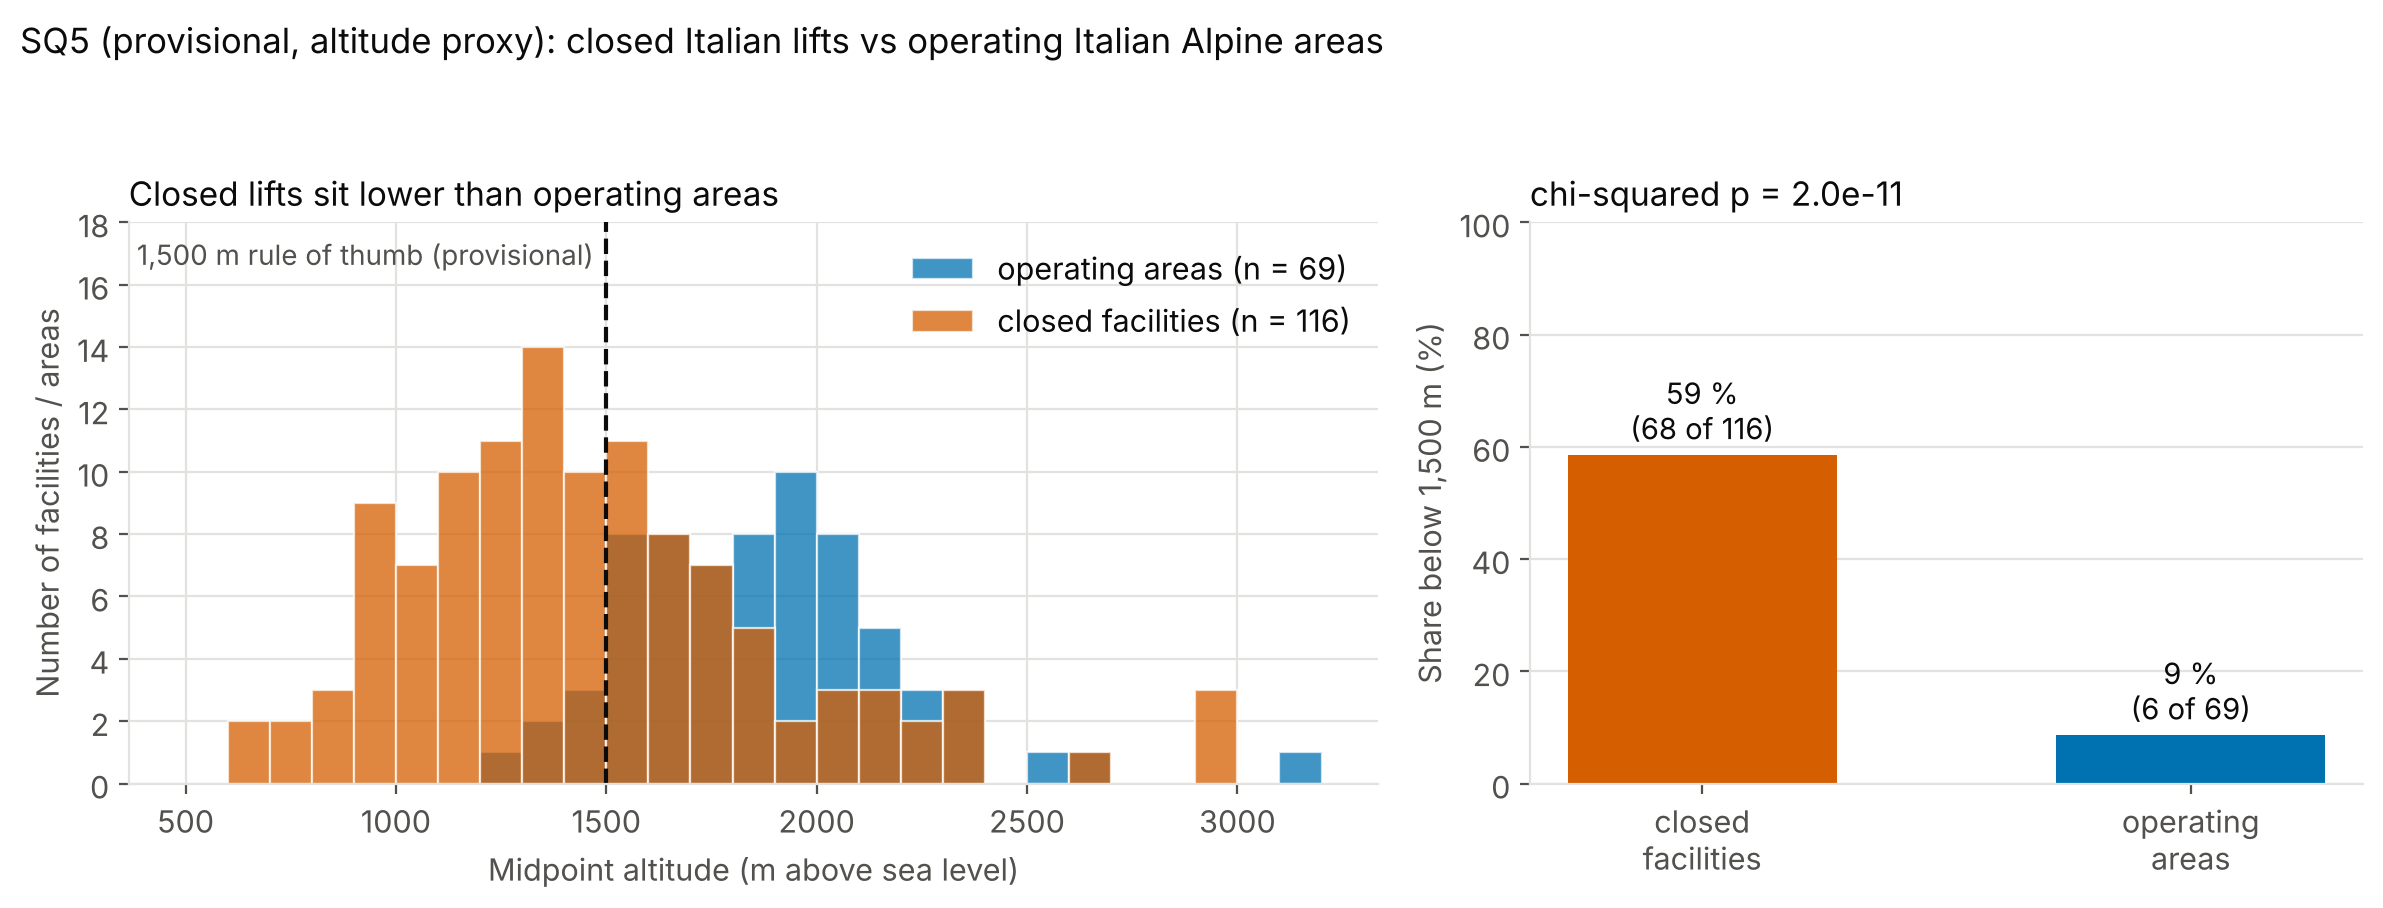

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1.5, 1]})

ax = axes[0]
bins = np.arange(500, 3201, 100)
ax.hist(operating["alt_mid"], bins=bins, color=COLOR_OPEN, alpha=0.75, edgecolor="white", linewidth=0.8, label=f"operating areas (n = {len(operating)})")
ax.hist(closed_alp["alt_mid"], bins=bins, color=COLOR_CLOSED, alpha=0.75, edgecolor="white", linewidth=0.8, label=f"closed facilities (n = {len(closed_alp)})")
ax.axvline(THRESHOLD_MAIN, color=INK, linewidth=1.5, linestyle="--")
ax.set_ylim(0, 18)
ax.text(THRESHOLD_MAIN - 30, 17.5, "1,500 m rule of thumb (provisional)", ha="right", va="top", color=INK_SOFT, fontsize=10)
ax.set_xlabel("Midpoint altitude (m above sea level)")
ax.set_ylabel("Number of facilities / areas")
ax.set_title("Closed lifts sit lower than operating areas", loc="left", fontsize=12)
ax.legend(frameon=False, loc="upper right")

ax = axes[1]
shares = [res_a["closed_at_risk"] / (res_a["closed_at_risk"] + res_a["closed_not"]), res_a["other_at_risk"] / (res_a["other_at_risk"] + res_a["other_not"])]
labels = ["closed\nfacilities", "operating\nareas"]
bars = ax.bar(labels, [s * 100 for s in shares], color=[COLOR_CLOSED, COLOR_OPEN], width=0.55)
for bar, share, (a, b) in zip(bars, shares, [(tab_a[0][0], sum(tab_a[0])), (tab_a[1][0], sum(tab_a[1]))]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1.5, f"{share * 100:.0f} %\n({a} of {b})", ha="center", va="bottom", fontsize=10.5)
ax.set_ylim(0, 100)
ax.set_ylabel("Share below 1,500 m (%)")
ax.set_title(f"chi-squared p = {res_a['p_value']:.1e}", loc="left", fontsize=12)
ax.grid(axis="x", visible=False)

fig.suptitle("SQ5 (provisional, altitude proxy): closed Italian lifts vs operating Italian Alpine areas", x=0.01, ha="left", fontsize=12.5, color=INK)
fig.tight_layout(rect=(0, 0, 1, 0.93))
fig.savefig(FIG_DIR / "sq5_closures_vs_operating.png", dpi=150)
plt.show()

## 7. Reading of the results

In [8]:
main = res_a
share_c, share_o = shares
ok_f, n_f, orf_min, orf_max, p_f = family_summary("fair")
ok_t, n_t, _, _, p_t = family_summary("towards")
ok_a, n_a, ora_min, ora_max, p_a = family_summary("against")
text = f'''
**Test A (main question).** {share_c * 100:.0f} % of the {len(closed_alp)} closed Alpine facilities have a midpoint altitude below {THRESHOLD_MAIN} m, against {share_o * 100:.0f} % of the {len(operating)} operating Italian Alpine areas. The chi-squared test gives chi2 = {main['chi2']:.1f} (1 degree of freedom), p = {main['p_value']:.1e}. The odds of being in the at-risk class are about {main['odds_ratio']:.0f} times larger for closed facilities (95 % CI {main['or_ci_low']:.0f} to {main['or_ci_high']:.0f}); Cramér's V = {main['cramers_v']:.2f} (a large association). All expected counts are at least 5 (smallest {main['min_expected']:.1f}), so the test is valid; the Fisher exact test agrees (p = {main['p_fisher']:.1e}).

**Robustness.** With the fair comparison (midpoint against midpoint) the association is significant at {ok_f} of {n_f} thresholds (odds ratios {orf_min:.1f} to {orf_max:.1f}, largest p = {p_f:.1e}); the threshold-free Mann-Whitney test agrees (p = {mw.pvalue:.1e}). With the comparison biased towards the effect it is significant at {ok_t} of {n_t} thresholds. Against the lowest point of the operating areas (a floor that is deliberately unfair to the effect) the association disappears: the association is significant with an odds ratio above 1 at {ok_a} of {n_a} thresholds, and the odds ratios are {ora_min:.2f} to {ora_max:.2f} (largest p = {p_a:.2f}), i.e. the closed lifts are *not* lower than the bottom of the operating areas. This is a floor check, not a refutation, but it shows that the finding exists only when a lift is compared with a like-for-like reference. The strength of the association should therefore be reported as "large with a fair comparison, depending on that choice", never as one number alone.

**Test B (status).** Among the closed facilities, {tab_b[0][0]} of {sum(tab_b[0])} permanently closed and {tab_b[1][0]} of {sum(tab_b[1])} temporarily closed facilities are at risk. The chi-squared p-value is {res_b['p_value']:.3f} (Fisher exact {res_b['p_fisher']:.3f}); at the 5 % level this is {'a significant' if res_b['p_value'] < 0.05 else 'not a significant'} difference. With only {sum(tab_b[1])} temporarily closed facilities the test has little power, so "no significant difference" must not be read as "no difference".

**What this means, and what it does not.** Closed lifts in the Italian Alps are concentrated at lower altitude than the areas that still operate. That is **consistent with** the idea that snow-poor locations are the ones that stop. It does **not** prove that missing snow caused the closures.
'''
display(Markdown(text))


**Test A (main question).** 59 % of the 116 closed Alpine facilities have a midpoint altitude below 1500 m, against 9 % of the 69 operating Italian Alpine areas. The chi-squared test gives chi2 = 44.9 (1 degree of freedom), p = 2.0e-11. The odds of being in the at-risk class are about 15 times larger for closed facilities (95 % CI 6 to 37); Cramér's V = 0.49 (a large association). All expected counts are at least 5 (smallest 27.6), so the test is valid; the Fisher exact test agrees (p = 2.3e-12).

**Robustness.** With the fair comparison (midpoint against midpoint) the association is significant at 3 of 3 thresholds (odds ratios 5.9 to 55.8, largest p = 1.0e-06); the threshold-free Mann-Whitney test agrees (p = 1.6e-11). With the comparison biased towards the effect it is significant at 3 of 3 thresholds. Against the lowest point of the operating areas (a floor that is deliberately unfair to the effect) the association disappears: the association is significant with an odds ratio above 1 at 0 of 3 thresholds, and the odds ratios are 0.33 to 0.62 (largest p = 0.13), i.e. the closed lifts are *not* lower than the bottom of the operating areas. This is a floor check, not a refutation, but it shows that the finding exists only when a lift is compared with a like-for-like reference. The strength of the association should therefore be reported as "large with a fair comparison, depending on that choice", never as one number alone.

**Test B (status).** Among the closed facilities, 63 of 102 permanently closed and 5 of 14 temporarily closed facilities are at risk. The chi-squared p-value is 0.063 (Fisher exact 0.084); at the 5 % level this is not a significant difference. With only 14 temporarily closed facilities the test has little power, so "no significant difference" must not be read as "no difference".

**What this means, and what it does not.** Closed lifts in the Italian Alps are concentrated at lower altitude than the areas that still operate. That is **consistent with** the idea that snow-poor locations are the ones that stop. It does **not** prove that missing snow caused the closures.


**Limitations (to state openly in the presentation)**

* **Proxy, not snow.** The class comes from altitude, not from measured days with natural snow. It will be replaced by the snow-risk class once the snow data are decided (Matiu et al. 2021 stations or CERRA-Land).
* **Strength depends on the comparison.** Against the most conservative reference (area base) the association is weak or absent at some thresholds; only the fair midpoint comparison and the one biased towards the effect give a large association.
* **Different units.** A closed facility is one lift (often a small local ski tow); an operating area is a whole resort, taken from a catalogue (skiresort.info) that lists mainly larger areas. Small low lifts are also closed for non-snow reasons (ownership, safety rules, running costs, low demand). The comparison therefore overstates how much of the difference is due to snow. The like-for-like midpoint comparison and the two bracketing checks reduce this problem, they do not remove it.
* **Selection of the operating group.** The operating areas are not a random sample of all operating lifts in Italy; small operating lifts are mostly missing.
* **Sample sizes.** Alpine closed facilities: 116; temporarily closed: 14 (test B has low power).
* **Cross-sectional association.** The data are a snapshot: no closing *year* is used. Analysing closures by year (`year_closed`) against climate change would need more cleaning (many entries are "anni '90", "n.d.").
* **Piemonte** includes some non-Alpine places; the Apennine regions are excluded from the main test and included in the sensitivity row.

In [9]:
out = pd.DataFrame([res_a, res_b] + rows)
out.insert(0, "test_id", ["A_main", "B_status"] + [f"S{i + 1}" for i in range(len(rows))])
out.to_csv(OUT_DIR / "sq5_chi_squared_results.csv", index=False)

(OUT_DIR / "sq5_status.json").write_text(json.dumps({
    "provisional": True,
    "risk_class": "altitude proxy: midpoint altitude below 1500 m (not days with snow)",
    "replace_with": "snow-risk class from SQ1 once the snow data for all places are decided",
    "n_closed_alpine": int(len(closed_alp)),
    "n_operating": int(len(operating)),
    "threshold_m": THRESHOLD_MAIN,
}, indent=2))

# ---- checks ----
assert len(closures) == 184 and closures["alt_mid"].notna().all()
assert len(closed_alp) == 116, len(closed_alp)
assert len(operating) == 69, len(operating)
assert sum(sum(r) for r in tab_a) == len(closed_alp) + len(operating)
assert sum(sum(r) for r in tab_b) == len(closed_alp)
assert main["p_value"] < 0.001 and main["odds_ratio"] > 1
assert abs(main["p_value"] - stats.chi2.sf(main["chi2"], 1)) < 1e-12
assert (sens.loc[sens["family"] == "fair", "p_value"] < 0.001).all()
assert (sens["family"].isin(["fair", "towards", "against", "all_italy"])).all()
assert (OUT_DIR / "sq5_chi_squared_results.csv").exists() and (FIG_DIR / "sq5_closures_vs_operating.png").exists()
print("All checks passed.")

All checks passed.
